In [1]:
from pathlib import Path
import zipfile

PASTA = Path.cwd()
arquivo_2015 = next(PASTA.glob("*2015*.ods"))

with zipfile.ZipFile(arquivo_2015, "r") as z:
    for item in z.infolist():
        if item.filename in ["content.xml", "styles.xml"]:
            print(
                item.filename,
                "| tamanho compactado:",
                round(item.compress_size / 1024**2, 2), "MB",
                "| tamanho original:",
                round(item.file_size / 1024**2, 2), "MB"
            )

content.xml | tamanho compactado: 52.97 MB | tamanho original: 2184.16 MB
styles.xml | tamanho compactado: 0.01 MB | tamanho original: 0.11 MB


In [2]:
import shutil

for programa in ["soffice", "libreoffice"]:
    caminho = shutil.which(programa)
    print(programa, ":", caminho)

soffice : None
libreoffice : None


In [3]:
from pathlib import Path

for arquivo in sorted(Path.cwd().iterdir()):
    if arquivo.is_file():
        print(arquivo.name)

Sinopse_Estatistica_da_Educação_Basica_2015.ods
Sinopse_Estatistica_da_Educação_Basica_2015.xlsx
Sinopse_Estatistica_da_Educação_Basica_2020.ods
Sinopse_Estatistica_da_Educação_Basica_2020.xlsx
Sinopse_Estatistica_da_Educação_Basica_2025_V2.ods
Sinopse_Estatistica_da_Educação_Basica_2025_V2.xlsx
Untitled.ipynb


In [4]:
from pathlib import Path

PASTA = Path.cwd()

for arquivo in sorted(PASTA.iterdir()):
    if arquivo.is_file():
        print(
            f"{arquivo.name} | "
            f"{arquivo.suffix} | "
            f"{arquivo.stat().st_size / (1024**2):.2f} MB"
        )

Sinopse_Estatistica_da_Educação_Basica_2015.ods | .ods | 53.31 MB
Sinopse_Estatistica_da_Educação_Basica_2015.xlsx | .xlsx | 83.73 MB
Sinopse_Estatistica_da_Educação_Basica_2020.ods | .ods | 52.06 MB
Sinopse_Estatistica_da_Educação_Basica_2020.xlsx | .xlsx | 79.30 MB
Sinopse_Estatistica_da_Educação_Basica_2025_V2.ods | .ods | 91.77 MB
Sinopse_Estatistica_da_Educação_Basica_2025_V2.xlsx | .xlsx | 189.70 MB
Untitled.ipynb | .ipynb | 0.00 MB


In [5]:
from pathlib import Path
import zipfile
import xml.etree.ElementTree as ET

PASTA = Path.cwd()

arquivo_2015 = next(PASTA.glob("*2015.xlsx"))

with zipfile.ZipFile(arquivo_2015, "r") as z:
    workbook_xml = z.read("xl/workbook.xml")

raiz = ET.fromstring(workbook_xml)

ns = {
    "main": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"
}

abas = raiz.findall(".//main:sheets/main:sheet", ns)

print("Abas do arquivo de 2015:")

for aba in abas:
    print("-", aba.attrib["name"])

Abas do arquivo de 2015:
- Sinopse Estatística
- Resumo
- Equipe Técnica
- Como Citar
- Sumário
- 1 - Matrículas
- Educação Básica 1.1
- 1.2
- 1.3
- 1.4
- Educação Infantil 1.5
- Creche 1.6
- 1.7
- 1.8
- 1.9
- Pré-Escola 1.10
- 1.11
- 1.12
- 1.13
- Ensino Fundamental 1.14
- Anos Iniciais 1.15
- 1.16
- 1.17
- 1.18
- 1.19
- Anos Finais 1.20
- 1.21
- 1.22
- 1.23
- 1.24
- Ensino Médio 1.25
- 1.26
- 1.27
- 1.28
- 1.29
- Educação Profissional 1.30
- 1.31
- 1.32
- 1.33
- EJA 1.34
- 1.35
- 1.36
- 1.37
- Educação Especial 1.38
- Classes Comuns 1.39
- 1.40
- 1.41
- 1.42
- 1.43
- 1.44
- Classes Exclusivas 1.45
- 1.46
- 1.47
- 1.48
- 1.49
- 1.50
- 2 - Docente
- Educação Básica 2.1
- 2.2
- 2.3
- 2.4
- 2.5
- Educação Infantil 2.6
- 2.7
- Creche 2.8
- 2.9
- 2.10
- 2.11
- Pré-Escola 2.12
- 2.13
- 2.14
- 2.15
- Ensino Fundamental 2.16
- 2.17
- 2.18
- 2.19
- 2.20
- Anos Iniciais 2.21
- 2.22
- 2.23
- 2.24
- Anos Finais 2.25
- 2.26
- 2.27
- 2.28
- Ensino Médio 2.29
- 2.30
- 2.31
- 2.32
- Educação Profissi

In [6]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()
arquivo_2015 = next(PASTA.glob("*2015.xlsx"))

print("Arquivo:", arquivo_2015.name)
print("Abrindo em modo de leitura...")

wb = load_workbook(
    arquivo_2015,
    read_only=True,
    data_only=True
)

abas_alvo = [
    "Educação Básica 1.1",
    "Educação Especial 1.38",
    "Classes Comuns 1.39",
    "Classes Exclusivas 1.45"
]

for nome in abas_alvo:
    if nome in wb.sheetnames:
        ws = wb[nome]

        print(f"\n{'=' * 60}")
        print("ABA:", nome)

        for linha in ws.iter_rows(
            min_row=1,
            max_row=15,
            values_only=True
        ):
            valores = [
                valor for valor in linha
                if valor is not None
            ]

            if valores:
                print(valores)
    else:
        print("\nAba não encontrada:", nome)

wb.close()

Arquivo: Sinopse_Estatistica_da_Educação_Basica_2015.xlsx
Abrindo em modo de leitura...

ABA: Educação Básica 1.1
['Voltar ao Sumário']
['MATRÍCULAS']
['Educação Básica ']
['1.1 –  Número de Matrículas da Educação Básica, por Etapa de Ensino, segundo a Região Geográfica, a Unidade da Federação e o Município - 2015']
['Região Geográfica', 'Unidade da Federação', 'Município', 'Código do Município', '                                                                                                                                         Número de Matrículas da Educação Básica']
['Total1-4', '                                                                                                                                     Etapa de Ensino ']
['Educação Infantil', 'Ensino Fundamental', 'Ensino Médio', 'Total10', 'Educação Profissional Técnica de Nível Médio', 'Educação Profissional - Formação Inicial Continuada (FIC)', 'Educação de Jovens e Adultos (EJA)', 'Educação Especial']
['Total5', 'Cre

In [7]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()
arquivo_2015 = next(PASTA.glob("*2015.xlsx"))

wb = load_workbook(
    arquivo_2015,
    read_only=True,
    data_only=True
)

for nome in wb.sheetnames:
    if any(nome.endswith(f"1.{n}") for n in range(40, 45)):
        ws = wb[nome]

        print("\n" + "=" * 70)
        print("ABA:", nome)

        for linha in ws.iter_rows(
            min_row=1,
            max_row=12,
            values_only=True
        ):
            valores = [v for v in linha if v is not None]
            if valores:
                print(valores)

wb.close()


ABA: 1.40
['Voltar ao Sumário']
['MATRÍCULAS']
['Educação Especial - Classes Comuns']
['1.40 – Número de Matrículas da Educação Especial em Classes Comuns, por Localização e Dependência Administrativa, segundo a Região Geográfica, a Unidade da Federação e o Município - 2015']
['Região Geográfica', 'Unidade da Federação', 'Município', 'Código do Município', 'Número de Matrículas da Educação Especial em Classes Comuns']
['Localização e Dependência Administrativa']
['Total1-3', 'Urbana', 'Rural']
['Total', 'Federal', 'Estadual', 'Municipal', 'Privada', 'Total', 'Federal', 'Estadual', 'Municipal', 'Privada']
['Brasil ', '  ', '  ', ' ', 750983, 652701, 1878, 226682, 377176, 46965, 98282, 235, 13184, 84464, 399]
['Norte ', '  ', '  ', ' ', 71724, 57378, 240, 22287, 31971, 2880, 14346, 21, 2392, 11899, 34]

ABA: 1.41
['Voltar ao Sumário']
['MATRÍCULAS']
['Educação Especial - Classes Comuns']
['1.41 – Número de Matrículas da Educação Especial em Classes Comuns, por Sexo e Cor/Raça, segundo a

In [8]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()
arquivo_2015 = next(PASTA.glob("*2015.xlsx"))

wb = load_workbook(
    arquivo_2015,
    read_only=True,
    data_only=True
)

for nome in wb.sheetnames:
    if any(nome.endswith(f"1.{n}") for n in range(46, 51)):
        ws = wb[nome]

        print("\n" + "=" * 70)
        print("ABA:", nome)

        for linha in ws.iter_rows(
            min_row=1,
            max_row=10,
            values_only=True
        ):
            valores = [v for v in linha if v is not None]
            if valores:
                print(valores)

wb.close()


ABA: 1.46
['Voltar ao Sumário']
['MATRÍCULAS']
['Educação Especial - Classes Exclusivas']
['1.46  – Número de Matrículas da Educação Especial em Classes Exclusivas, por Localização e Dependência Administrativa, segundo a Região Geográfica, a Unidade da Federação e o Município - 2015.']
['Região Geográfica', 'Unidade da Federação', 'Município', 'Código do Município', '  Número de Matrículas da Educação Especial em Classes Exclusivas ']
['   Localização e Dependência Administrativa']
['Total1-3', 'Urbana', 'Rural']
['Total', 'Federal', 'Estadual', 'Municipal', 'Privada', 'Total', 'Federal', 'Estadual', 'Municipal', 'Privada']

ABA: 1.47
['Voltar ao Sumário']
['MATRÍCULAS']
['Educação Especial - Classes Exclusivas']
['1.47 – Número de Matrículas da Educação Especial em Classes Exclusivas, por Sexo e Cor/Raça, segundo a Região Geográfica, a Unidade da Federação e o Município - 2015.']
['Região Geográfica', 'Unidade da Federação', 'Município', 'Código do Município', 'Total1-3', 'Número de 

In [9]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()
arquivo_2015 = next(PASTA.glob("*2015.xlsx"))

wb = load_workbook(
    arquivo_2015,
    read_only=True,
    data_only=True
)

for nome in ["1.40", "1.46"]:
    ws = wb[nome]

    print("\n" + "=" * 60)
    print("ABA:", nome)

    for linha in ws.iter_rows(
        min_row=9,
        max_row=9,
        values_only=True
    ):
        print(linha)

wb.close()


ABA: 1.40
(None, None, None, None, None, 'Total', 'Federal', 'Estadual', 'Municipal', 'Privada', 'Total', 'Federal', 'Estadual', 'Municipal', 'Privada', None, None, None, None, None, None, None)

ABA: 1.46
(None, None, None, None, None, 'Total', 'Federal', 'Estadual', 'Municipal', 'Privada', 'Total', 'Federal', 'Estadual', 'Municipal', 'Privada', None, None, None, None, None, None, None)


In [10]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()
arquivo_2015 = next(PASTA.glob("*2015.xlsx"))

wb = load_workbook(
    arquivo_2015,
    read_only=True,
    data_only=True
)

for nome in ["1.40", "1.46"]:
    ws = wb[nome]

    print("\n" + "=" * 70)
    print("ABA:", nome)

    for linha in ws.iter_rows(values_only=True):
        if linha and str(linha[0]).strip() == "Brasil":
            for i, valor in enumerate(linha):
                if valor is not None:
                    print(f"Coluna {i}: {valor}")
            break

wb.close()


ABA: 1.40
Coluna 0: Brasil 
Coluna 1:   
Coluna 2:   
Coluna 3:  
Coluna 4: 750983
Coluna 5: 652701
Coluna 6: 1878
Coluna 7: 226682
Coluna 8: 377176
Coluna 9: 46965
Coluna 10: 98282
Coluna 11: 235
Coluna 12: 13184
Coluna 13: 84464
Coluna 14: 399

ABA: 1.46
Coluna 0: Brasil 
Coluna 1:   
Coluna 2:   
Coluna 3:  
Coluna 4: 179700
Coluna 5: 177922
Coluna 6: 728
Coluna 7: 16817
Coluna 8: 30098
Coluna 9: 130279
Coluna 10: 1778
Coluna 11: 0
Coluna 12: 107
Coluna 13: 378
Coluna 14: 1293


In [11]:
import pandas as pd

dados_2015 = pd.DataFrame({
    "Rede": ["Pública", "Privada"],
    "Classes comuns": [
        (1878 + 226682 + 377176) + (235 + 13184 + 84464),
        46965 + 399
    ],
    "Classes exclusivas": [
        (728 + 16817 + 30098) + (0 + 107 + 378),
        130279 + 1293
    ]
})

dados_2015["Total educação especial"] = (
    dados_2015["Classes comuns"]
    + dados_2015["Classes exclusivas"]
)

dados_2015["Percentual em classes comuns (%)"] = (
    dados_2015["Classes comuns"]
    / dados_2015["Total educação especial"]
    * 100
)

display(dados_2015.round(2))

print("\nVerificação dos totais:")
print("Classes comuns:", dados_2015["Classes comuns"].sum())
print("Classes exclusivas:", dados_2015["Classes exclusivas"].sum())
print("Total:", dados_2015["Total educação especial"].sum())

,Rede,Classes comuns,Classes exclusivas,Total educação especial,Percentual em classes comuns (%)
0,Pública,703619,48128,751747,93.60
1,Privada,47364,131572,178936,26.47



Verificação dos totais:
Classes comuns: 750983
Classes exclusivas: 179700
Total: 930683


In [12]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()

arquivos = [
    next(PASTA.glob("*2015.xlsx")),
    next(PASTA.glob("*2020.xlsx")),
    next(PASTA.glob("*2025*.xlsx"))
]

for arquivo in arquivos:
    print("\n" + "=" * 65)
    print("ARQUIVO:", arquivo.name)

    wb = load_workbook(
        arquivo,
        read_only=True,
        data_only=True
    )

    for nome in wb.sheetnames:
        if (
            "Classes Comuns" in nome
            or "Classes Exclusivas" in nome
        ):
            print("-", nome)

    wb.close()


ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2015.xlsx
- Classes Comuns 1.39
- Classes Exclusivas 1.45
- Classes Comuns 2.44
- Classes Exclusivas 2.50
- Classes Comuns 3.28
- Classes Exclusivas 3.31
- Classes Comuns 4.19
- Classes Exclusivas 4.21

ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2020.xlsx
- Classes Comuns 1.39
- Classes Exclusivas 1.45
- Classes Comuns 2.44
- Classes Exclusivas 2.50
- Classes Comuns 3.28
- Classes Exclusivas 3.31
- Classes Comuns 4.19
- Classes Exclusivas 4.21

ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2025_V2.xlsx
- Classes Comuns 1.60
- Classes Exclusivas 1.67
- Classes Comuns 2.62
- Classes Exclusivas 2.69
- Classes Comuns 3.48
- Classes Exclusivas 3.52
- Classes Comuns 4.44
- Classes Exclusivas 4.48


In [13]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()

arquivos = [
    next(PASTA.glob("*2015.xlsx")),
    next(PASTA.glob("*2020.xlsx")),
    next(PASTA.glob("*2025*.xlsx"))
]

for arquivo in arquivos:
    print("\n" + "=" * 70)
    print("ANO/ARQUIVO:", arquivo.name)

    wb = load_workbook(
        arquivo,
        read_only=True,
        data_only=True
    )

    for nome in wb.sheetnames:
        nome_limpo = nome.strip().lower()

        if (
            "classes comuns" in nome_limpo
            or "classes exclusivas" in nome_limpo
        ):
            # Mostra somente abas cujo nome contém o tema desejado
            print(nome)

    wb.close()


ANO/ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2015.xlsx
Classes Comuns 1.39
Classes Exclusivas 1.45
Classes Comuns 2.44
Classes Exclusivas 2.50
Classes Comuns 3.28
Classes Exclusivas 3.31
Classes Comuns 4.19
Classes Exclusivas 4.21

ANO/ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2020.xlsx
Classes Comuns 1.39
Classes Exclusivas 1.45
Classes Comuns 2.44
Classes Exclusivas 2.50
Classes Comuns 3.28
Classes Exclusivas 3.31
Classes Comuns 4.19
Classes Exclusivas 4.21

ANO/ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2025_V2.xlsx
Classes Comuns 1.60
Classes Exclusivas 1.67
Classes Comuns 2.62
Classes Exclusivas 2.69
Classes Comuns 3.48
Classes Exclusivas 3.52
Classes Comuns 4.44
Classes Exclusivas 4.48


In [14]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()

arquivos = [
    next(PASTA.glob("*2015.xlsx")),
    next(PASTA.glob("*2020.xlsx")),
    next(PASTA.glob("*2025*.xlsx"))
]

for arquivo in arquivos:
    print("\n" + "=" * 75)
    print("ARQUIVO:", arquivo.name)

    wb = load_workbook(
        arquivo,
        read_only=True,
        data_only=True
    )

    for nome in wb.sheetnames:
        nome_limpo = nome.strip().lower()

        if "classes comuns" not in nome_limpo and "classes exclusivas" not in nome_limpo:
            continue

        ws = wb[nome]

        # Procura o título da tabela nas primeiras linhas
        for linha in ws.iter_rows(
            min_row=1,
            max_row=8,
            values_only=True
        ):
            texto = " ".join(
                str(v) for v in linha if v is not None
            )

            if "dependência administrativa" in texto.lower():
                print(f"{nome}: {texto.strip()}")
                break

    wb.close()


ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2015.xlsx

ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2020.xlsx

ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2025_V2.xlsx


In [15]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()

arquivos = [
    next(PASTA.glob("*2015.xlsx")),
    next(PASTA.glob("*2020.xlsx")),
    next(PASTA.glob("*2025*.xlsx"))
]

for arquivo in arquivos:
    print("\n" + "=" * 80)
    print("ARQUIVO:", arquivo.name)

    wb = load_workbook(
        arquivo,
        read_only=True,
        data_only=True
    )

    for nome in wb.sheetnames:
        if "classes comuns" not in nome.lower() and "classes exclusivas" not in nome.lower():
            continue

        ws = wb[nome]

        for num_linha, linha in enumerate(
            ws.iter_rows(min_row=1, max_row=10, values_only=True),
            start=1
        ):
            valores = [v for v in linha if v is not None]

            texto = " ".join(str(v) for v in valores)

            if any(
                termo in texto.lower()
                for termo in [
                    "dependência administrativa",
                    "localização",
                    "matrículas da educação especial"
                ]
            ):
                print(f"\nABA: {nome} | LINHA {num_linha}")
                print(texto[:500])

    wb.close()


ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2015.xlsx

ABA: Classes Comuns 1.39 | LINHA 4
1.39 – Número de Matrículas da Educação Especial em Classes Comuns, por Etapa de Ensino, segundo a Região Geográfica, a Unidade da Federação e o Município - 2015

ABA: Classes Comuns 1.39 | LINHA 6
Região Geográfica Unidade da Federação Município Código do Município                                                                                                                    Número de Matrículas da Educação Especial em Classes Comuns

ABA: Classes Exclusivas 1.45 | LINHA 4
1.45 – Número de Matrículas da Educação Especial em Classes Exclusivas, por Etapa de Ensino, segundo a Região Geográfica, a Unidade da Federação e o Município - 2015

ABA: Classes Exclusivas 1.45 | LINHA 6
Região Geográfica Unidade da Federação Município Código do Município                                                                                                             Número de Matrículas da Educação Especia

In [16]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()

arquivos = [
    next(PASTA.glob("*2015.xlsx")),
    next(PASTA.glob("*2020.xlsx")),
    next(PASTA.glob("*2025*.xlsx"))
]

for arquivo in arquivos:
    print("\n" + "=" * 75)
    print("ARQUIVO:", arquivo.name)

    wb = load_workbook(
        arquivo,
        read_only=True,
        data_only=True
    )

    for nome in wb.sheetnames:
        ws = wb[nome]

        # Lê somente as primeiras 8 linhas de cada aba
        for linha in ws.iter_rows(
            min_row=1,
            max_row=8,
            values_only=True
        ):
            texto = " ".join(
                str(v) for v in linha if v is not None
            ).lower()

            if (
                "dependência administrativa" in texto
                and (
                    "classes comuns" in texto
                    or "classes exclusivas" in texto
                )
            ):
                print(f"- {nome}: {texto[:250]}")
                break

    wb.close()


ARQUIVO: Sinopse_Estatistica_da_Educação_Basica_2015.xlsx
- 1.40: 1.40 – número de matrículas da educação especial em classes comuns, por localização e dependência administrativa, segundo a região geográfica, a unidade da federação e o município - 2015
- 1.44: 1.44 – número de matrículas da educação especial em classes comuns em tempo integral (turmas presenciais) e parcial, por dependência administrativa, segundo a região geográfica, a unidade da federação e o município - 2015
- 1.46: 1.46  – número de matrículas da educação especial em classes exclusivas, por localização e dependência administrativa, segundo a região geográfica, a unidade da federação e o município - 2015.
- 1.50: 1.50 – número de matrículas da educação especial em classes exclusivas em tempo integral (turmas presenciais) e parcial, por dependência administrativa, segundo a região geográfica, a unidade da federação e o município - 2015
- 2.45: 2.45 – número de docentes da educação especial em classes comuns, por loc

In [17]:
from pathlib import Path
from openpyxl import load_workbook

PASTA = Path.cwd()

configuracao = {
    2015: {
        "arquivo": next(PASTA.glob("*2015.xlsx")),
        "abas": ["1.40", "1.46"]
    },
    2020: {
        "arquivo": next(PASTA.glob("*2020.xlsx")),
        "abas": ["1.40", "1.46"]
    },
    2025: {
        "arquivo": next(PASTA.glob("*2025*.xlsx")),
        "abas": ["1.56"]
    }
}

for ano, dados in configuracao.items():
    print("\n" + "=" * 90)
    print("ANO:", ano)

    wb = load_workbook(
        dados["arquivo"],
        read_only=True,
        data_only=True
    )

    for nome in dados["abas"]:
        if nome not in wb.sheetnames:
            print(f"Aba {nome} não encontrada.")
            continue

        ws = wb[nome]

        print(f"\n--- ABA {nome} ---")

        for numero, linha in enumerate(
            ws.iter_rows(min_row=1, max_row=12, values_only=True),
            start=1
        ):
            valores = [
                (i, str(v).strip()[:100])
                for i, v in enumerate(linha)
                if v is not None and str(v).strip()
            ]

            if valores:
                print(f"Linha {numero}: {valores}")

            if any(
                isinstance(v, str) and v.strip().lower() == "brasil"
                for v in linha
                if v is not None
            ):
                break

    wb.close()


ANO: 2015

--- ABA 1.40 ---
Linha 1: [(0, 'Voltar ao Sumário')]
Linha 2: [(0, 'MATRÍCULAS')]
Linha 3: [(0, 'Educação Especial - Classes Comuns')]
Linha 4: [(0, '1.40 – Número de Matrículas da Educação Especial em Classes Comuns, por Localização e Dependência Ad')]
Linha 6: [(0, 'Região Geográfica'), (1, 'Unidade da Federação'), (2, 'Município'), (3, 'Código do Município'), (4, 'Número de Matrículas da Educação Especial em Classes Comuns')]
Linha 7: [(4, 'Localização e Dependência Administrativa')]
Linha 8: [(4, 'Total1-3'), (5, 'Urbana'), (10, 'Rural')]
Linha 9: [(5, 'Total'), (6, 'Federal'), (7, 'Estadual'), (8, 'Municipal'), (9, 'Privada'), (10, 'Total'), (11, 'Federal'), (12, 'Estadual'), (13, 'Municipal'), (14, 'Privada')]
Linha 11: [(0, 'Brasil'), (4, '750983'), (5, '652701'), (6, '1878'), (7, '226682'), (8, '377176'), (9, '46965'), (10, '98282'), (11, '235'), (12, '13184'), (13, '84464'), (14, '399')]

--- ABA 1.46 ---
Linha 1: [(0, 'Voltar ao Sumário')]
Linha 2: [(0, 'MATRÍCULA

In [18]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Matrículas em classes comuns e exclusivas,
# somando as áreas urbana e rural.

dados = [
    # Ano, Rede, Classes comuns, Classes exclusivas
    (2015, "Pública", 703619, 48128),
    (2015, "Privada",  47364, 131572),
    (2020, "Pública", 1071774, 38730),
    (2020, "Privada",   81101, 117295),
]

df = pd.DataFrame(
    dados,
    columns=["Ano", "Rede", "Classes comuns", "Classes exclusivas"]
)

# Total de matrículas da Educação Especial em cada rede
df["Total"] = df["Classes comuns"] + df["Classes exclusivas"]

# Percentual de matrículas em classes comuns
df["Percentual"] = (
    df["Classes comuns"] / df["Total"] * 100
)

display(df.round(2))


,Ano,Rede,Classes comuns,Classes exclusivas,Total,Percentual
0,2015,Pública,703619,48128,751747,93.60
1,2015,Privada,47364,131572,178936,26.47
2,2020,Pública,1071774,38730,1110504,96.51
3,2020,Privada,81101,117295,198396,40.88


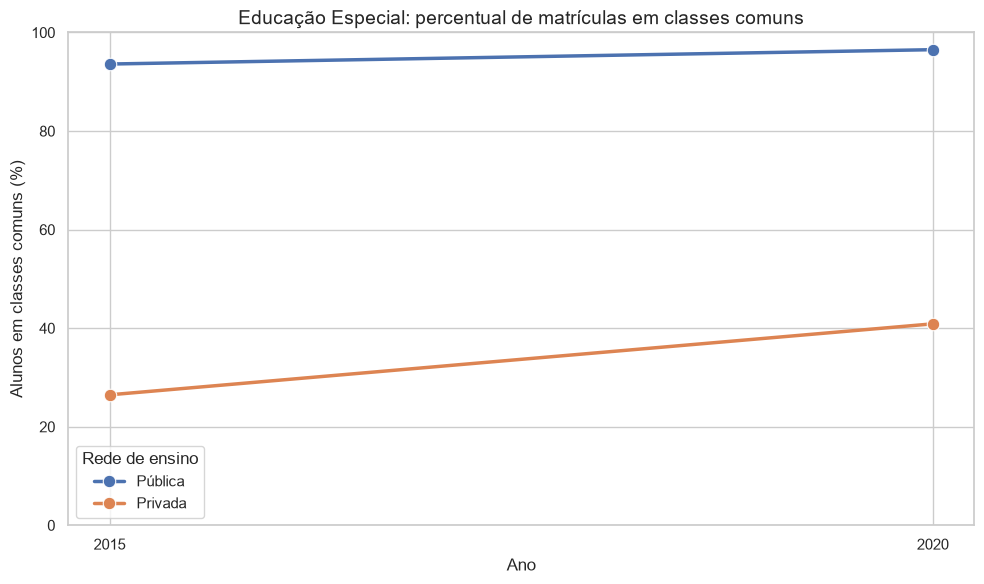

In [19]:

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df,
    x="Ano",
    y="Percentual",
    hue="Rede",
    marker="o",
    linewidth=2.5,
    markersize=9
)

plt.title(
    "Educação Especial: percentual de matrículas em classes comuns",
    fontsize=14
)
plt.xlabel("Ano")
plt.ylabel("Alunos em classes comuns (%)")
plt.xticks([2015, 2020])
plt.ylim(0, 100)
plt.legend(title="Rede de ensino")
plt.tight_layout()
plt.show()


In [20]:

# Organizar os percentuais por ano e rede
tabela = df.pivot(
    index="Ano",
    columns="Rede",
    values="Percentual"
)

tabela["Diferença (p.p.)"] = (
    tabela["Pública"] - tabela["Privada"]
)

tabela = tabela.rename(columns={
    "Pública": "Rede pública (%)",
    "Privada": "Rede privada (%)"
})

display(tabela.round(2))


Rede,Rede privada (%),Rede pública (%),Diferença (p.p.)
Ano,,,
2015,26.47,93.60,67.13
2020,40.88,96.51,55.63


In [22]:

import pandas as pd

arquivo_2025 = "Sinopse_Estatistica_da_Educação_Basica_2025_V2.xlsx"

# Ler as duas tabelas de matrículas
comuns_2025 = pd.read_excel(
    arquivo_2025,
    sheet_name="1.61",
    header=None
)

exclusivas_2025 = pd.read_excel(
    arquivo_2025,
    sheet_name="1.68",
    header=None
)

print("CLASSES COMUNS — 2025")
display(comuns_2025.head(15))

print("CLASSES EXCLUSIVAS — 2025")
display(exclusivas_2025.head(15))


CLASSES COMUNS — 2025


,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
0,Voltar ao Sumário,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MATRÍCULAS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Educação Especial - Classes Comuns,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.61 – Número de Matrículas da Educação Especi...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Região Geográfica,Unidade da Federação,Município,Código do Município,Número de Matrículas da Educação Especial em C...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,Total,Rede Pública,NaN,NaN,NaN,Rede Privada,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,Total,Federal,Estadual,Municipal,Total,...,Rural,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Total,Rede Pública,NaN,NaN,NaN,Rede Privada,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,Total,Federal,Estadual,Municipal,Total,Particular,Comunitária,Confessional,Filantrópica


CLASSES EXCLUSIVAS — 2025


,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
0,Voltar ao Sumário,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MATRÍCULAS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Educação Especial - Classes Exclusivas,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.68 – Número de Matrículas da Educação Especi...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Região Geográfica,Unidade da Federação,Município,Código do Município,Número de Matrículas da Educação Especial em C...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,Total,Rede Pública,NaN,NaN,NaN,Rede Privada,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,Total,Federal,Estadual,Municipal,Total,...,Rural,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Total,Rede Pública,NaN,NaN,NaN,Rede Privada,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,Total,Federal,Estadual,Municipal,Total,Particular,Comunitária,Confessional,Filantrópica


In [23]:

print("Linhas que contêm Brasil — classes comuns:")
display(comuns_2025[
    comuns_2025.astype(str).apply(
        lambda coluna: coluna.str.contains(
            "Brasil", case=False, na=False
        )
    ).any(axis=1)
])

print("Linhas que contêm Brasil — classes exclusivas:")
display(exclusivas_2025[
    exclusivas_2025.astype(str).apply(
        lambda coluna: coluna.str.contains(
            "Brasil", case=False, na=False
        )
    ).any(axis=1)
])


Linhas que contêm Brasil — classes comuns:


,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
11,Brasil,,,,2298005,2065252,13115,609240,1442897,232753,...,252584,250280,1291,31970,217019,2304,880,712,59,653
42,Norte,Rondônia,Nova Brasilândia D'Oeste,1100148,180,180,0,73,107,0,...,29,29,0,0,29,0,0,0,0,0
68,Norte,Acre,Assis Brasil,1200054,237,237,0,132,105,0,...,51,51,0,36,15,0,0,0,0,0
69,Norte,Acre,Brasiléia,1200104,616,616,0,289,327,0,...,62,62,0,20,42,0,0,0,0,0
193,Norte,Pará,Brasil Novo,1501725,271,263,0,27,236,8,...,71,71,0,1,70,0,0,0,0,0
356,Norte,Tocantins,Brasilândia do Tocantins,1703602,12,12,0,6,6,0,...,0,0,0,0,0,0,0,0,0,0
724,Nordeste,Piauí,Brasileira,2201960,117,117,0,10,107,0,...,30,30,0,0,30,0,0,0,0,0
2149,Nordeste,Bahia,Pau Brasil,2923902,195,193,0,19,174,2,...,16,16,0,11,5,0,0,0,0,0
2368,Sudeste,Minas Gerais,Brasilândia de Minas,3108552,223,222,0,119,103,1,...,0,0,0,0,0,0,0,0,0,0
3321,Sudeste,São Paulo,Américo Brasiliense,3501707,258,241,0,53,188,17,...,0,0,0,0,0,0,0,0,0,0


Linhas que contêm Brasil — classes exclusivas:


,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
11,Brasil,,,,160154,40780,773,8941,31066,119374,...,2630,1117,19,91,1007,1513,1,2,0,1510
42,Norte,Rondônia,Nova Brasilândia D'Oeste,1100148,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
68,Norte,Acre,Assis Brasil,1200054,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69,Norte,Acre,Brasiléia,1200104,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
193,Norte,Pará,Brasil Novo,1501725,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
356,Norte,Tocantins,Brasilândia do Tocantins,1703602,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
724,Nordeste,Piauí,Brasileira,2201960,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2149,Nordeste,Bahia,Pau Brasil,2923902,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2368,Sudeste,Minas Gerais,Brasilândia de Minas,3108552,46,0,0,0,0,46,...,0,0,0,0,0,0,0,0,0,0
3321,Sudeste,São Paulo,Américo Brasiliense,3501707,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [24]:

# Mostrar todas as colunas e as primeiras linhas das classes comuns
print("CLASSES COMUNS — 2025")
print("Dimensões:", comuns_2025.shape)
display(comuns_2025.head(13).T)

# Mostrar todas as colunas e as primeiras linhas das classes exclusivas
print("CLASSES EXCLUSIVAS — 2025")
print("Dimensões:", exclusivas_2025.shape)
display(exclusivas_2025.head(13).T)


CLASSES COMUNS — 2025
Dimensões: (5620, 34)


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,Voltar ao Sumário,MATRÍCULAS,Educação Especial - Classes Comuns,1.61 – Número de Matrículas da Educação Especi...,NaN,Região Geográfica,NaN,NaN,NaN,NaN,NaN,Brasil,Norte
1,NaN,NaN,NaN,NaN,NaN,Unidade da Federação,NaN,NaN,NaN,NaN,NaN,,
2,NaN,NaN,NaN,NaN,NaN,Município,NaN,NaN,NaN,NaN,NaN,,
3,NaN,NaN,NaN,NaN,NaN,Código do Município,NaN,NaN,NaN,NaN,NaN,,
4,NaN,NaN,NaN,NaN,NaN,Número de Matrículas da Educação Especial em C...,Total,NaN,NaN,NaN,NaN,2298005,233629
5,NaN,NaN,NaN,NaN,NaN,NaN,Rede Pública,Total,NaN,NaN,NaN,2065252,216908
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Federal,NaN,NaN,NaN,13115,1380
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Estadual,NaN,NaN,NaN,609240,70092
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Municipal,NaN,NaN,NaN,1442897,145436
9,NaN,NaN,NaN,NaN,NaN,NaN,Rede Privada,Total,NaN,NaN,NaN,232753,16721


CLASSES EXCLUSIVAS — 2025
Dimensões: (5620, 34)


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,Voltar ao Sumário,MATRÍCULAS,Educação Especial - Classes Exclusivas,1.68 – Número de Matrículas da Educação Especi...,NaN,Região Geográfica,NaN,NaN,NaN,NaN,NaN,Brasil,Norte
1,NaN,NaN,NaN,NaN,NaN,Unidade da Federação,NaN,NaN,NaN,NaN,NaN,,
2,NaN,NaN,NaN,NaN,NaN,Município,NaN,NaN,NaN,NaN,NaN,,
3,NaN,NaN,NaN,NaN,NaN,Código do Município,NaN,NaN,NaN,NaN,NaN,,
4,NaN,NaN,NaN,NaN,NaN,Número de Matrículas da Educação Especial em C...,Total,NaN,NaN,NaN,NaN,160154,6078
5,NaN,NaN,NaN,NaN,NaN,NaN,Rede Pública,Total,NaN,NaN,NaN,40780,2791
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Federal,NaN,NaN,NaN,773,0
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Estadual,NaN,NaN,NaN,8941,853
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Municipal,NaN,NaN,NaN,31066,1938
9,NaN,NaN,NaN,NaN,NaN,NaN,Rede Privada,Total,NaN,NaN,NaN,119374,3287


In [25]:

# Totais nacionais de 2025, extraídos da linha do Brasil
dados_2025 = [
    (2025, "Pública", 2065252, 40780),
    (2025, "Privada", 232753, 119374),
]

df_2025 = pd.DataFrame(
    dados_2025,
    columns=["Ano", "Rede", "Classes comuns", "Classes exclusivas"]
)

df_2025["Total"] = (
    df_2025["Classes comuns"] + df_2025["Classes exclusivas"]
)

df_2025["Percentual"] = (
    df_2025["Classes comuns"] / df_2025["Total"] * 100
)

display(df_2025.round(2))


,Ano,Rede,Classes comuns,Classes exclusivas,Total,Percentual
0,2025,Pública,2065252,40780,2106032,98.06
1,2025,Privada,232753,119374,352127,66.10


,Ano,Rede,Classes comuns,Classes exclusivas,Total,Percentual
0,2015,Pública,703619,48128,751747,93.60
1,2015,Privada,47364,131572,178936,26.47
2,2020,Pública,1071774,38730,1110504,96.51
3,2020,Privada,81101,117295,198396,40.88
4,2025,Pública,2065252,40780,2106032,98.06
5,2025,Privada,232753,119374,352127,66.10


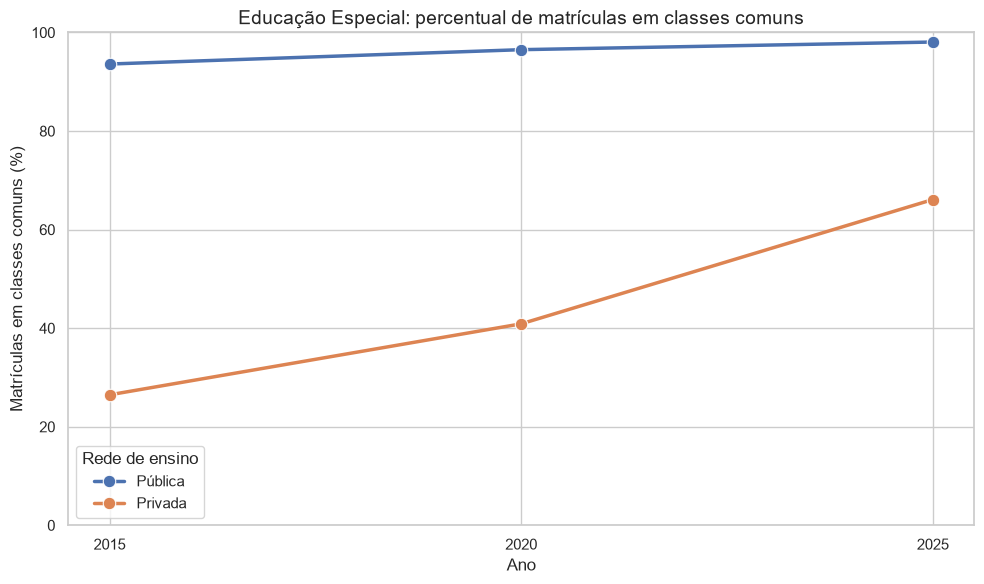

In [26]:

# Juntar os dados dos três anos
df_final = pd.concat(
    [df, df_2025],
    ignore_index=True
)

# Conferir a tabela completa
display(
    df_final[
        ["Ano", "Rede", "Classes comuns",
         "Classes exclusivas", "Total", "Percentual"]
    ].round(2)
)

# Gráfico de linhas
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df_final,
    x="Ano",
    y="Percentual",
    hue="Rede",
    marker="o",
    linewidth=2.5,
    markersize=9
)

plt.title(
    "Educação Especial: percentual de matrículas em classes comuns",
    fontsize=14
)
plt.xlabel("Ano")
plt.ylabel("Matrículas em classes comuns (%)")
plt.xticks([2015, 2020, 2025])
plt.ylim(0, 100)
plt.legend(title="Rede de ensino")
plt.tight_layout()
plt.show()


In [27]:

tabela_final = df_final.pivot(
    index="Ano",
    columns="Rede",
    values="Percentual"
)

tabela_final["Diferença (p.p.)"] = (
    tabela_final["Pública"] - tabela_final["Privada"]
)

tabela_final = tabela_final.rename(columns={
    "Pública": "Rede pública (%)",
    "Privada": "Rede privada (%)"
})

display(tabela_final.round(2))


Rede,Rede privada (%),Rede pública (%),Diferença (p.p.)
Ano,,,
2015,26.47,93.60,67.13
2020,40.88,96.51,55.63
2025,66.10,98.06,31.96


In [28]:

# Conferir a base final
display(
    df_final[
        ["Ano", "Rede", "Classes comuns",
         "Classes exclusivas", "Total", "Percentual"]
    ].sort_values(["Ano", "Rede"]).round(2)
)

# Verificar se há exatamente 6 observações
print("Número de observações:", len(df_final))
print("Anos:", sorted(df_final["Ano"].unique()))
print("Redes:", sorted(df_final["Rede"].unique()))

assert len(df_final) == 6, "A base deve ter 6 observações."
assert set(df_final["Ano"]) == {2015, 2020, 2025}


,Ano,Rede,Classes comuns,Classes exclusivas,Total,Percentual
1,2015,Privada,47364,131572,178936,26.47
0,2015,Pública,703619,48128,751747,93.60
3,2020,Privada,81101,117295,198396,40.88
2,2020,Pública,1071774,38730,1110504,96.51
5,2025,Privada,232753,119374,352127,66.10
4,2025,Pública,2065252,40780,2106032,98.06


Número de observações: 6
Anos: [np.int64(2015), np.int64(2020), np.int64(2025)]
Redes: ['Privada', 'Pública']


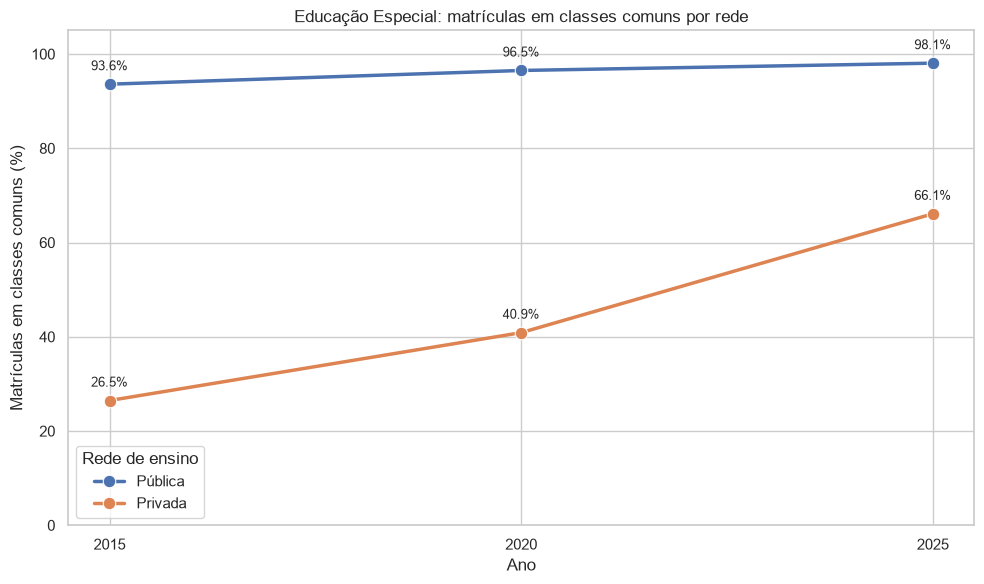

In [29]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(
    data=df_final,
    x="Ano",
    y="Percentual",
    hue="Rede",
    marker="o",
    linewidth=2.5,
    markersize=9,
    ax=ax
)

# Mostrar os percentuais ao lado de cada ponto
for _, linha in df_final.iterrows():
    ax.annotate(
        f'{linha["Percentual"]:.1f}%',
        (linha["Ano"], linha["Percentual"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9
    )

ax.set(
    title="Educação Especial: matrículas em classes comuns por rede",
    xlabel="Ano",
    ylabel="Matrículas em classes comuns (%)",
    xticks=[2015, 2020, 2025],
    ylim=(0, 105)
)

ax.legend(title="Rede de ensino")
plt.tight_layout()
plt.show()
